Cell types: ['Immune Stromal Interface', 'Metabolic-like IABTS', 'Immune-adapted IABTS', 'Differentiated Tumor Core', 'Others']
Categories (5, object): ['Differentiated Tumor Core', 'Immune Stromal Interface', 'Immune-adapted IABTS', 'Metabolic-like IABTS', 'Others']
Color mapping: {'Immune Stromal Interface': 'blue', 'Metabolic-like IABTS': 'red', 'Immune-adapted IABTS': 'yellow', 'Differentiated Tumor Core': 'green'}
Cell types to display: ['Immune Stromal Interface', 'Metabolic-like IABTS', 'Immune-adapted IABTS', 'Differentiated Tumor Core']
Processing nS01-LN...
Found 156401 cells for nS01-LN
  Immune Stromal Interface: 17241 cells
  Metabolic-like IABTS: 103832 cells
  Immune-adapted IABTS: 4035 cells
  Differentiated Tumor Core: 31232 cells
Processing nS07-LN...
Found 21370 cells for nS07-LN
  Immune Stromal Interface: 7212 cells
  Metabolic-like IABTS: 7128 cells
  Immune-adapted IABTS: 6162 cells
  Differentiated Tumor Core: 868 cells
Processing nS02...
Found 77467 cells for n

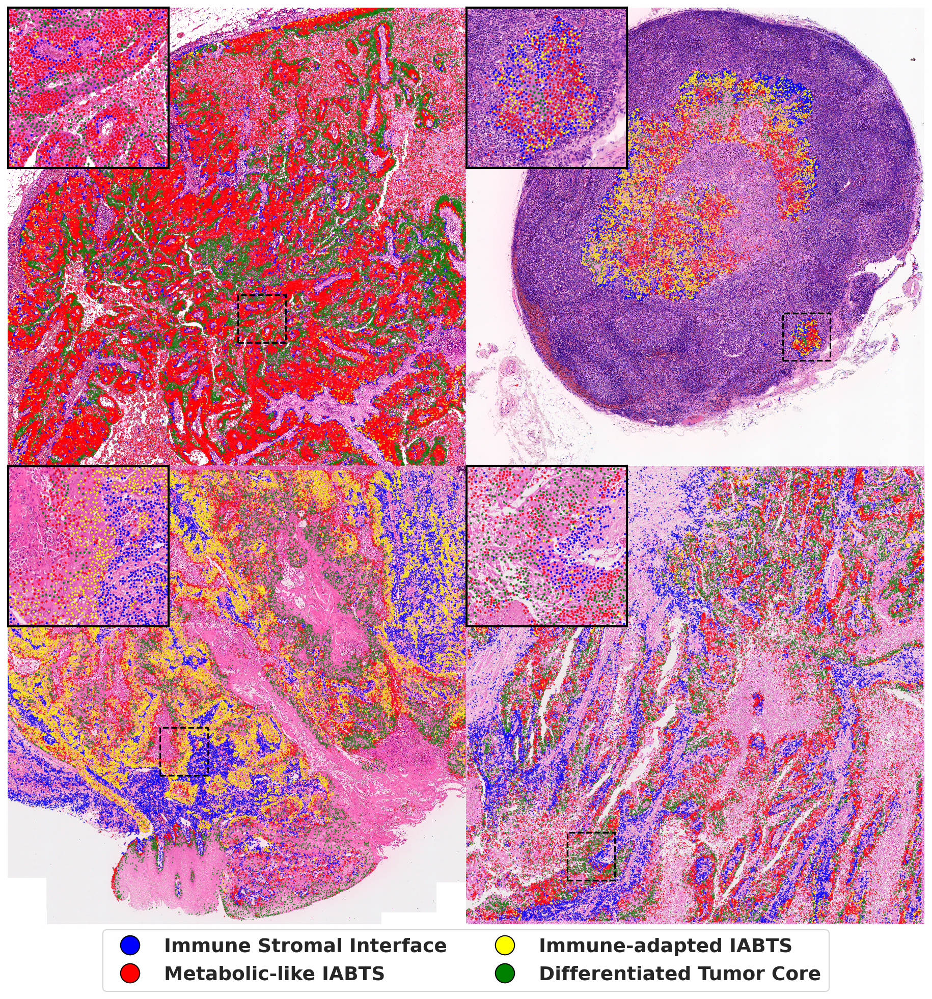

In [14]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import scanpy as sc
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from matplotlib.patches import Rectangle
import matplotlib.gridspec as gridspec

# Allow loading of ultra-large images
Image.MAX_IMAGE_PIXELS = None

# ================= Configuration Area (Manual adjustment interface) =================
epi_merged = sc.read_h5ad("./h5ad/epi_merged.h5ad")

samples_info = [
    ('nS01-LN', "nS01_LN.tif", "nS01-LN"),
    ('nS07-LN', "nS07_LN.tif", "nS07-LN"),
    ('nS02',    "nS02.tif",    "nS02"),
    ('nS01',     "nS01.tif",     "nS01"),
]

sample_configs = [
    {
        "batch_id": 'nS01-LN',
        "row": 0, "col": 0,
        "crop_params": {"center_x": 9500, "center_y": 6000, "size": 1500}, 
        "inset_fraction": 0.35,
        "inset_pad": 0.02
    },
    {
        "batch_id": 'nS07-LN',
        "row": 0, "col": 1,
        "crop_params": {"center_x": 10000, "center_y": 4950, "size": 1200},
        "inset_fraction": 0.35,
        "inset_pad": 0.02
    },
    {
        "batch_id": 'nS02',
        "row": 1, "col": 0,
        "crop_params": {"center_x": 7000, "center_y": 5500, "size": 1500},
        "inset_fraction": 0.35,
        "inset_pad": 0.02
    },
    {
        "batch_id": 'nS01',
        "row": 1, "col": 1,
        "crop_params": {"center_x": 5500, "center_y": 3500, "size": 1500},
        "inset_fraction": 0.35,
        "inset_pad": 0.02
    }
]

# ================= Main Program Logic =================

# Create figure and precisely control subplot spacing
fig = plt.figure(figsize=(12, 12))
# Use GridSpec for precise control, set spacing to 0
gs = gridspec.GridSpec(2, 2, figure=fig, wspace=0, hspace=0, left=0, right=1, bottom=0, top=1)

axes = []
for i in range(2):
    for j in range(2):
        ax = fig.add_subplot(gs[i, j])
        axes.append(ax)

# Get all unique cell types
unique_types = epi_merged.obs['type'].unique()
print(f"Cell types: {unique_types}")

# Define color mapping - red, blue, yellow, green; Others are not colored
colors_for_types = ['blue', 'red', 'yellow', 'green']
color_mapping = {}

# Assign colors to cell types other than Others
other_types = [t for t in unique_types if t != 'Others']
for i, cell_type in enumerate(other_types[:4]):  # Take only the first 4 types
    color_mapping[cell_type] = colors_for_types[i % len(colors_for_types)]

# Others are not displayed and not added to color_mapping
# This way Others will not be plotted

print(f"Color mapping: {color_mapping}")
print(f"Cell types to display: {list(color_mapping.keys())}")

for i, config in enumerate(sample_configs):
    batch_id = config["batch_id"]
    
    info_item = next((item for item in samples_info if item[0] == batch_id), None)
    if not info_item:
        continue
        
    c1, c2, c3 = info_item
    ax = axes[i]
    
    print(f"Processing {batch_id}...")

    try:
        # Filter current batch data directly from epi_merged
        mask_batch = epi_merged.obs['batch'] == batch_id
        adata_sub = epi_merged[mask_batch].copy()
        
        if adata_sub.n_obs == 0:
            print(f"No data for {batch_id}")
            continue
            
        coords = adata_sub.obsm["spatial"]
        # Use the type column directly as labels
        labels = adata_sub.obs['type'].values
        print(f"Found {len(labels)} cells for {batch_id}")
        
        # Count the number of each cell type
        for cell_type in color_mapping.keys():
            count = np.sum(labels == cell_type)
            if count > 0:
                print(f"  {cell_type}: {count} cells")
        
    except Exception as e:
        print(f"Error processing data for {batch_id}: {e}")
        continue

    # Calculate main plot display range (keep square)
    x_min_all, x_max_all = coords[:, 0].min(), coords[:, 0].max()
    y_min_all, y_max_all = coords[:, 1].min(), coords[:, 1].max()
    
    span_x = x_max_all - x_min_all
    span_y = y_max_all - y_min_all
    
    if span_x > span_y:
        y_center = (y_min_all + y_max_all) / 2
        y_min_all = y_center - span_x / 2
        y_max_all = y_center + span_x / 2
    else:
        x_center = (x_min_all + x_max_all) / 2
        x_min_all = x_center - span_y / 2
        x_max_all = x_center + span_y / 2
    
    x_min_all, x_max_all, y_min_all, y_max_all = map(int, [x_min_all, x_max_all, y_min_all, y_max_all])
    
    # Process background image
    try:
        with Image.open("./organize_photos/"+c2) as img_full:
            # Ensure crop range is within image bounds
            w, h = img_full.size
            x_min_clamped = max(0, min(x_min_all, w))
            x_max_clamped = max(0, min(x_max_all, w))
            y_min_clamped = max(0, min(y_min_all, h))
            y_max_clamped = max(0, min(y_max_all, h))
            
            img_cropped = img_full.crop((x_min_clamped, y_min_clamped, x_max_clamped, y_max_clamped))
            img_cropped = img_cropped.transpose(Image.FLIP_TOP_BOTTOM)
            img_array = np.array(img_cropped)
    except Exception as e:
        print(f"Error loading image for {batch_id}: {e}")
        continue
    
    # Draw main plot
    ax.imshow(
        img_array,
        extent=[x_min_clamped, x_max_clamped, y_min_clamped, y_max_clamped],
        aspect='equal',
        interpolation='none',
        origin='upper'
    )
    
    # Only plot cell types with assigned colors (excluding Others)
    for cell_type in color_mapping.keys():
        mask_type = labels == cell_type
        if np.any(mask_type):
            ax.scatter(
                coords[mask_type, 0], coords[mask_type, 1],
                c=color_mapping[cell_type], s=1.33, alpha=0.8, edgecolors='none',
                label=cell_type
            )
    
    ax.set_xlim(x_min_clamped, x_max_clamped)
    ax.set_ylim(y_min_clamped, y_max_clamped)
    ax.set_axis_off()
    
    # Remove border gaps between subplots
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Local zoom (inset) logic
    cp = config["crop_params"]
    center_x, center_y, size = cp["center_x"], cp["center_y"], cp["size"]
    inset_frac = config["inset_fraction"]
    inset_pad = config["inset_pad"]
    
    half_size = size / 2
    ix_min, ix_max = center_x - half_size, center_x + half_size
    iy_min, iy_max = center_y - half_size, center_y + half_size
    
    # Create inset plot, positioned at upper left
    ax_ins = inset_axes(ax, width=f"{inset_frac*100}%", height=f"{inset_frac*100}%", 
                        loc='upper left', borderpad=inset_pad)
    
    try:
        with Image.open("./organize_photos/"+c2) as img_full:
            w, h = img_full.size
            ix_min_clamped = max(0, int(ix_min))
            iy_min_clamped = max(0, int(iy_min))
            ix_max_clamped = min(w, int(ix_max))
            iy_max_clamped = min(h, int(iy_max))
            
            img_inset_crop = img_full.crop((ix_min_clamped, iy_min_clamped, ix_max_clamped, iy_max_clamped))
            img_inset_crop = img_inset_crop.transpose(Image.FLIP_TOP_BOTTOM)
            img_inset_array = np.array(img_inset_crop)
    except Exception as e:
        print(f"Error loading inset for {batch_id}: {e}")
        continue
    
    ax_ins.imshow(
        img_inset_array,
        extent=[ix_min_clamped, ix_max_clamped, iy_min_clamped, iy_max_clamped],
        aspect='equal',
        interpolation='none',
        origin='upper'
    )
    
    # Plot points in the inset (only cell types with assigned colors)
    mask_inset_range = (coords[:, 0] >= ix_min_clamped) & (coords[:, 0] <= ix_max_clamped) & \
                       (coords[:, 1] >= iy_min_clamped) & (coords[:, 1] <= iy_max_clamped)
    
    for cell_type in color_mapping.keys():
        mask_type = labels == cell_type
        mask_combined = mask_type & mask_inset_range
        if np.any(mask_combined):
            ax_ins.scatter(
                coords[mask_combined, 0], coords[mask_combined, 1],
                c=color_mapping[cell_type], s=4.0, alpha=0.9, edgecolors='none'
            )
    
    ax_ins.set_xlim(ix_min_clamped, ix_max_clamped)
    ax_ins.set_ylim(iy_min_clamped, iy_max_clamped)
    
    # Hide tick labels but keep borders
    ax_ins.set_xticks([])
    ax_ins.set_yticks([])
    ax_ins.spines['top'].set_visible(True)
    ax_ins.spines['right'].set_visible(True)
    ax_ins.spines['bottom'].set_visible(True)
    ax_ins.spines['left'].set_visible(True)
    
    # Set border style
    for spine in ax_ins.spines.values():
        spine.set_color('black')
        spine.set_linewidth(2)
        spine.set_zorder(10)

    # Add rectangle box on the main plot
    rect = Rectangle(
        (ix_min_clamped, iy_min_clamped),
        ix_max_clamped - ix_min_clamped,
        iy_max_clamped - iy_min_clamped,
        linewidth=1.5, edgecolor='black', facecolor='none', 
        zorder=5, linestyle='--'
    )
    ax.add_patch(rect)

# Add legend to the center of the 4 plots
from matplotlib.lines import Line2D
legend_elements = []
for cell_type, color in color_mapping.items():
    legend_elements.append(Line2D([0], [0], marker='o', color='w', 
                                  markerfacecolor=color, markersize=18, markeredgecolor='black', markeredgewidth=1, label=cell_type))

# Calculate center position (center of 2x2 grid)
# Using figure coordinates, the center is approximately (0.5, 0.5)
fig.legend(handles=legend_elements, loc='center', 
           prop={'weight': 'bold', "size": 18}, frameon=True, ncol=len(legend_elements)//2,
           bbox_to_anchor=(0.5, -0.04), bbox_transform=fig.transFigure)

plt.show()